# Песочница паттернов GoF: Strategy, Factory Method, Observer

**Учебное задание (2 ч).** Среда — Google Colab, язык — Java. Каждый пример представлен **одним файлом** `.java` и запускается без отдельной компиляции командой `java Файл.java` (запуск исходного файла, Java 11 и выше).

**Идея задания.** Паттерн изучается не по описанию, а по разнице: сначала запускается код «до» — работающий, но жёстко связанный; затем тот же сценарий переписывается на паттерн, и проверки доказывают, что **поведение не изменилось**, а **новое требование добавляется без правки старого кода**.

**Состав работы**

| Раздел | Паттерн | Что делает студент |
|---|---|---|
| 2 | Strategy | **образец** — разобран полностью, нужно только запустить и разобраться |
| 3 | Factory Method | задача: самостоятельно переписать код «до» |
| 4 | Observer | задача: самостоятельно переписать код «до» |
| 5–6 | — | сравнение, выводы, контрольные вопросы |

**Правила оформления, от которых зависит автопроверка**

1. Имена файлов строго: `TariffAfter.java`, `FactoryAfter.java`, `ObserverAfter.java`.
2. В каждом файле **первым** идёт открытый класс с методом `main` — иначе запуск исходного файла не работает.
3. Каждый файл сам себя проверяет: печатает строки `[OK]` / `[FAIL]` и бросает `AssertionError`, если хотя бы одна проверка не пройдена.
4. Идентификаторы — латиницей и описательно (`tariffStrategy`, а не `ts`), комментарии — по-русски.
5. К каждому паттерну — диаграмма классов в файле `*.puml`.

**Сдача.** Все файлы `.java`, `.puml`, сам блокнот и вывод ячейки самопроверки — в pull request.

## 1. Подготовка среды

In [9]:
# 1.1 Проверить, какая Java доступна в среде.
# Нужна версия 11 или выше: только с неё работает запуск одного исходного файла (java Файл.java).
!java -version
!javac -version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
javac 21.0.12.1


Если версия ниже 11, запуск одного исходного файла недоступен — всюду в блокноте вместо `!java Файл.java` используйте два шага: `!javac Файл.java && java Файл`.

Проверка «живого» запуска (ячейка 1.2 записывает файл, 1.3 — запускает):

In [11]:
%%writefile Hello.java
public class Hello {
    public static void main(String[] args) {
        System.out.println("Среда готова, Java работает: " + System.getProperty("java.version"));
    }
}

Overwriting Hello.java


In [12]:
!java Hello.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Среда готова, Java работает: 21.0.12.1


---

## 2. Образец: Strategy (разобран полностью)

**Сценарий.** Расчёт платы за перевозку груза. Плата зависит от вида отправки: повагонная, контейнерная, маршрутная. Формулы учебные.

### 2.1 Код «до»: один метод знает про все виды отправок

In [17]:
%%writefile TariffBefore.java
// Код «до»: вид отправки разбирается условным оператором внутри одного метода.
public class TariffBefore {

    public static void main(String[] args) {
        System.out.printf("повагонная   : %10.2f%n", cost("WAGON", 60, 500));
        System.out.printf("контейнерная : %10.2f%n", cost("CONTAINER", 24, 500));
        System.out.printf("маршрутная   : %10.2f%n", cost("BLOCK_TRAIN", 3000, 500));
        System.out.printf("рефрижератор : %10.2f%n", cost("REFRIGERATED", 60, 500));
    }

    static double cost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;   // про новый вид отправки метод не знает
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

Overwriting TariffBefore.java


In [18]:
!java TariffBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
повагонная   :     510.00
контейнерная :     508.00
маршрутная   :   10500.00
рефрижератор :       0.00


### 2.2 Разбор: что именно плохо

Запустив код «до», обратите внимание:

* рефрижераторная отправка дала **0.00** — метод о ней не знает, и единственный способ это исправить — залезть внутрь уже работающего метода;
* каждый новый вид отправки удлиняет один и тот же метод, то есть нарушает **принцип открытости/закрытости** (открыт для расширения, закрыт для изменения);
* метод одновременно отвечает за выбор варианта и за сам расчёт — нарушение **единственной ответственности**;
* протестировать один вид отправки отдельно от остальных нельзя.

**Что делает Strategy.** Каждый вариант расчёта становится отдельным классом с общим интерфейсом, а вызывающий код работает с интерфейсом и больше не знает перечня вариантов.

### 2.3 Код «после»: вариант расчёта вынесен в стратегию

In [38]:
%%writefile TariffAfter.java
import java.util.LinkedHashMap;
import java.util.Map;

public class TariffAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        Map<String, TariffStrategy> tariffCatalog = new LinkedHashMap<>();
        tariffCatalog.put("WAGON", new WagonTariff());
        tariffCatalog.put("CONTAINER", new ContainerTariff());
        tariffCatalog.put("BLOCK_TRAIN", new BlockTrainTariff());

        TariffCalculator tariffCalculator = new TariffCalculator();

        System.out.println("--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---");
        for (Map.Entry<String, TariffStrategy> catalogEntry : tariffCatalog.entrySet()) {
            double calculatedCost = tariffCalculator.calculate(catalogEntry.getValue(), 60, 500);
            System.out.printf("%-12s %-28s %10.2f%n",
                    catalogEntry.getKey(), catalogEntry.getValue().title(), calculatedCost);
        }

        System.out.println();
        System.out.println("--- Характеризующие тесты: поведение совпадает с кодом «до» ---");
        check("повагонная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("WAGON"), 60, 500),
                           legacyCost("WAGON", 60, 500)));
        check("контейнерная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("CONTAINER"), 24, 500),
                           legacyCost("CONTAINER", 24, 500)));
        check("маршрутная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("BLOCK_TRAIN"), 3000, 500),
                           legacyCost("BLOCK_TRAIN", 3000, 500)));

        System.out.println();
        System.out.println("--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---");
        TariffStrategy refrigeratedTariff = new TariffStrategy() {
            public double cost(double massTons, int distanceKm) {
                return 1.80 * massTons * distanceKm / 100.0 + 600.0;
            }
            public String title() {
                return "рефрижераторная отправка";
            }
        };
        double refrigeratedCost = tariffCalculator.calculate(refrigeratedTariff, 60, 500);
        System.out.printf("%-12s %-28s %10.2f%n", "REFRIGERATED", refrigeratedTariff.title(), refrigeratedCost);
        check("новая стратегия рассчитана, класс TariffCalculator не изменён", refrigeratedCost > 0.0);
        check("в коде «до» тот же вид отправки давал нуль", legacyCost("REFRIGERATED", 60, 500) == 0.0);

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    static boolean equalMoney(double firstValue, double secondValue) {
        return Math.abs(firstValue - secondValue) < 0.01;
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    static double legacyCost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

interface TariffStrategy {
    double cost(double massTons, int distanceKm);
    String title();
}

class TariffCalculator {
    double calculate(TariffStrategy tariffStrategy, double massTons, int distanceKm) {
        double calculatedValue = tariffStrategy.cost(massTons, distanceKm);
        return Math.round(calculatedValue * 100.0) / 100.0;
    }
}

class WagonTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 1.20 * massTons * distanceKm / 100.0 + 150.0;
    }
    public String title() {
        return "повагонная отправка";
    }
}

class ContainerTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.90 * massTons * distanceKm / 100.0 + 400.0;
    }
    public String title() {
        return "контейнерная отправка";
    }
}

class BlockTrainTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.70 * massTons * distanceKm / 100.0;
    }
    public String title() {
        return "маршрутная отправка";
    }
}

Overwriting TariffAfter.java


In [22]:
!java TariffAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---
WAGON        повагонная отправка              510.00
CONTAINER    контейнерная отправка            670.00
BLOCK_TRAIN  маршрутная отправка              210.00

--- Характеризующие тесты: поведение совпадает с кодом «до» ---
[OK]   повагонная отправка
[OK]   контейнерная отправка
[OK]   маршрутная отправка

--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---
REFRIGERATED рефрижераторная отправка        1140.00
[OK]   новая стратегия рассчитана, класс TariffCalculator не изменён
[OK]   в коде «до» тот же вид отправки давал нуль

Все проверки пройдены.


### 2.4 Диаграмма классов образца

Установка PlantUML занимает около минуты и выполняется один раз за сеанс.

In [23]:
!apt-get -qq install -y plantuml > /dev/null && echo "PlantUML установлен"

PlantUML установлен


In [39]:
%%writefile strategy.puml
@startuml
title Strategy: расчёт платы за перевозку (образец)

interface TariffStrategy {
  +cost(massTons, distanceKm) : double
  +title() : String
}

class TariffCalculator {
  +calculate(tariffStrategy, massTons, distanceKm) : double
}

class WagonTariff
class ContainerTariff
class BlockTrainTariff

TariffCalculator o--> TariffStrategy : использует
TariffStrategy <|.. WagonTariff
TariffStrategy <|.. ContainerTariff
TariffStrategy <|.. BlockTrainTariff
@enduml

Overwriting strategy.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


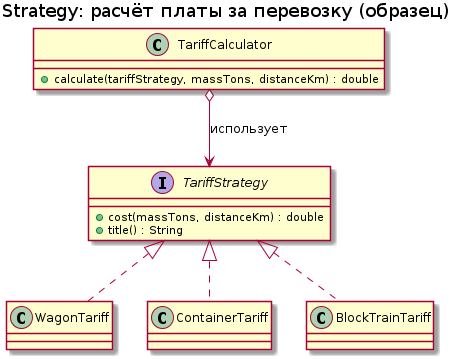

In [40]:
!plantuml -tpng strategy.puml
from IPython.display import Image
Image("strategy.png")

### 2.5 Вопросы к образцу (ответить текстом в этой ячейке)

1. Какие классы пришлось бы изменить в коде «до» и в коде «после», чтобы добавить рефрижераторную отправку?
   **Ответ:** _(заполнить)_
2. Зачем в файле оставлен метод `legacyCost`, если он больше не используется в расчёте?
   **Ответ:** _(заполнить)_
3. Что произойдёт, если в каталоге не окажется запрошенного вида отправки, и как это следует обработать?
   **Ответ:** _(заполнить)_

**Ответы 2.5 (Чарачкин И. А., ГИ-41, вариант 7)**

1. В коде «до» пришлось бы менять метод `cost` внутри `TariffBefore`. В коде «после» — только добавить новый класс `RefrigeratedTariff`, старые классы не трогаем.
2. `legacyCost` оставлен как эталон поведения: характеризующие тесты доказывают, что новая реализация считает так же, как старая.
3. Если вида отправки нет в каталоге, `tariffCatalog.get(...)` вернёт `null` → `NullPointerException`. Следует проверять наличие и бросать осмысленное исключение (или возвращать `Optional`/ошибку), а не молча считать `0.00`.

---

## 3. Задача 1: Factory Method

**Сценарий.** Описание вагона по его типу: крытый, платформа, цистерна. Ниже — код «до», построенный на той же ошибке: условный оператор вместо полиморфизма.

### 3.1 Код «до» (запустить, не изменяя)

In [26]:
%%writefile FactoryBefore.java
// Код «до»: создание и описание объекта подменены разбором строкового типа.
public class FactoryBefore {

    public static void main(String[] args) {
        System.out.println(describe("COVERED", 68));
        System.out.println(describe("PLATFORM", 71));
        System.out.println(describe("TANK", 66));
        System.out.println(describe("HOPPER", 70));   // новый тип — обработчика нет
    }

    static String describe(String wagonType, double capacityTons) {
        if (wagonType.equals("COVERED")) {
            return "Крытый вагон: грузоподъёмность " + capacityTons + " т, тарные и штучные грузы";
        } else if (wagonType.equals("PLATFORM")) {
            return "Платформа: грузоподъёмность " + capacityTons + " т, длинномерные и тяжеловесные грузы";
        } else if (wagonType.equals("TANK")) {
            return "Цистерна: грузоподъёмность " + capacityTons + " т, наливные грузы";
        }
        return "Неизвестный тип вагона: " + wagonType;
    }
}

Writing FactoryBefore.java


In [27]:
!java FactoryBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Крытый вагон: грузоподъёмность 68.0 т, тарные и штучные грузы
Платформа: грузоподъёмность 71.0 т, длинномерные и тяжеловесные грузы
Цистерна: грузоподъёмность 66.0 т, наливные грузы
Неизвестный тип вагона: HOPPER


### 3.2 Задание

Переписать сценарий на **Factory Method** в файле `FactoryAfter.java`. Требования:

1. Общий тип продукта: интерфейс или абстрактный класс `Wagon` с методами `description()` и `capacityTons()`.
2. Не менее трёх конкретных продуктов: `CoveredWagon`, `Platform`, `TankWagon`.
3. Создатель с фабричным методом: абстрактный класс или интерфейс `WagonCreator` с методом `createWagon(double capacityTons)` и конкретные создатели для каждого типа.
4. Вызывающий код (`main`) работает **только** с типами `WagonCreator` и `Wagon` и не содержит ни одного `if` по типу вагона.
5. Четвёртый тип (`HopperWagon`, зерновоз) добавляется **новым классом**, без правки ранее написанных классов; это должно быть видно по коду.
6. Проверки в файле (метод `check`, как в образце), минимум четыре:
   * описание каждого из трёх типов не пустое и содержит грузоподъёмность;
   * тип созданного объекта соответствует ожидаемому создателю;
   * четвёртый тип работает наравне с остальными;
   * метод `main` не содержит разбора типов (проверяется глазами преподавателя, в код выносить не нужно).
7. При неуспешной проверке — `throw new AssertionError(...)`.

**Подсказка по структуре файла:** первым идёт `public class FactoryAfter` с `main`, после него — интерфейсы и классы паттерна (как в `TariffAfter.java`).

In [57]:
%%writefile FactoryAfter.java
// Фабричный метод: создание отцепов разных типов (вариант 7, сортировочная станция).
// Чарачкин Илья Александрович, группа ГИ-41.
public class FactoryAfter {
    static int failed = 0;

    public static void main(String[] args) {
        WagonCreator singleCreator = new SingleCarCreator();
        WagonCreator groupCreator = new GroupCreator();
        WagonCreator routeCreator = new RouteCreator();
        WagonCreator transferCreator = new TransferTrainCreator(); // четвёртый тип

        Cut single = singleCreator.createCut(1);
        Cut group = groupCreator.createCut(5);
        Cut route = routeCreator.createCut(40);
        Cut transfer = transferCreator.createCut(60);

        System.out.println(single.description());
        System.out.println(group.description());
        System.out.println(route.description());
        System.out.println(transfer.description());

        check("одиночный отцеп: описание не пустое",
                single.description() != null && !single.description().isEmpty());
        check("групповой отцеп: содержит число вагонов",
                group.description().contains("5"));
        check("маршрутный отцеп: правильный тип",
                route instanceof RouteCut);
        check("передаточный поезд (4-й тип) работает",
                transfer instanceof TransferTrainCut && transfer.wagonCount() == 60);

        failIfNeeded();
        System.out.println("Все проверки пройдены.");
    }

    static void failIfNeeded() {
        if (failed > 0) throw new AssertionError("Провалено проверок: " + failed);
    }

    static void check(String name, boolean ok) {
        System.out.println((ok ? "[OK]   " : "[FAIL] ") + name);
        if (!ok) failed++;
    }
}

interface Cut {
    String description();
    int wagonCount();
}

class SingleCarCut implements Cut {
    private final int wagonCount;
    SingleCarCut(int wagonCount) { this.wagonCount = wagonCount; }
    public String description() { return "Одиночный отцеп: 1 вагон, направляется на сортировочный путь"; }
    public int wagonCount() { return wagonCount; }
}

class GroupCut implements Cut {
    private final int wagonCount;
    GroupCut(int wagonCount) { this.wagonCount = wagonCount; }
    public String description() { return "Групповой отцеп: " + wagonCount + " вагонов, подборка по назначению"; }
    public int wagonCount() { return wagonCount; }
}

class RouteCut implements Cut {
    private final int wagonCount;
    RouteCut(int wagonCount) { this.wagonCount = wagonCount; }
    public String description() { return "Маршрутный отцеп: " + wagonCount + " вагонов, готов к отправке целым составом"; }
    public int wagonCount() { return wagonCount; }
}

class TransferTrainCut implements Cut {
    private final int wagonCount;
    TransferTrainCut(int wagonCount) { this.wagonCount = wagonCount; }
    public String description() { return "Передаточный поезд: " + wagonCount + " вагонов, передача на соседнюю станцию"; }
    public int wagonCount() { return wagonCount; }
}

interface WagonCreator {
    Cut createCut(int wagonCount);
}

class SingleCarCreator implements WagonCreator {
    public Cut createCut(int wagonCount) { return new SingleCarCut(wagonCount); }
}
class GroupCreator implements WagonCreator {
    public Cut createCut(int wagonCount) { return new GroupCut(wagonCount); }
}
class RouteCreator implements WagonCreator {
    public Cut createCut(int wagonCount) { return new RouteCut(wagonCount); }
}
class TransferTrainCreator implements WagonCreator {
    public Cut createCut(int wagonCount) { return new TransferTrainCut(wagonCount); }
}

Overwriting FactoryAfter.java


In [58]:
!java FactoryAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Одиночный отцеп: 1 вагон, направляется на сортировочный путь
Групповой отцеп: 5 вагонов, подборка по назначению
Маршрутный отцеп: 40 вагонов, готов к отправке целым составом
Передаточный поезд: 60 вагонов, передача на соседнюю станцию
[OK]   одиночный отцеп: описание не пустое
[OK]   групповой отцеп: содержит число вагонов
[OK]   маршрутный отцеп: правильный тип
[OK]   передаточный поезд (4-й тип) работает
Все проверки пройдены.


In [46]:
%%writefile factory.puml
@startuml
title Factory Method: создание отцепа (вариант 7, ГИ-41)

interface Cut {
  +description() : String
  +wagonCount() : int
}

class SingleCarCut
class GroupCut
class RouteCut
class TransferTrainCut

interface WagonCreator {
  +createCut(wagonCount) : Cut
}

class SingleCarCreator
class GroupCreator
class RouteCreator
class TransferTrainCreator

WagonCreator <|.. SingleCarCreator
WagonCreator <|.. GroupCreator
WagonCreator <|.. RouteCreator
WagonCreator <|.. TransferTrainCreator
Cut <|.. SingleCarCut
Cut <|.. GroupCut
Cut <|.. RouteCut
Cut <|.. TransferTrainCut
SingleCarCreator ..> SingleCarCut : создаёт
GroupCreator ..> GroupCut : создаёт
RouteCreator ..> RouteCut : создаёт
TransferTrainCreator ..> TransferTrainCut : создаёт
@enduml

Overwriting factory.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


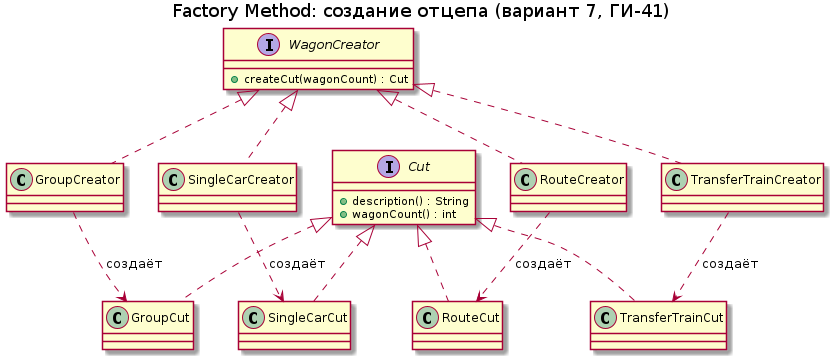

In [47]:
!plantuml -tpng factory.puml
from IPython.display import Image
Image("factory.png")

Вывод по задаче 1 (Чарачкин И. А., ГИ-41, вариант 7): фабричный метод скрывает от вызывающего кода конкретный класс создаваемого отцепа — `main` работает только с `WagonCreator` и `Cut`, поэтому новый тип отцепа (`TransferTrainCut`, передаточный поезд) добавляется одним новым классом создателя без правки существующих. Прямое `new` жёстко привязало бы код к конкретному классу. Фабрика излишня, если тип отцепа никогда не меняется и создание тривиально — тогда она добавляет лишний слой классов без выгоды.

---

## 4. Задача 2: Observer

**Сценарий.** Станция фиксирует прибытие поезда и должна оповестить получателей: табло, журнал, рассылку. В коде «до» станция сама знает про всех получателей.

### 4.1 Код «до» (запустить, не изменяя)

In [48]:
%%writefile ObserverBefore.java
// Код «до»: источник события жёстко связан со всеми получателями.
public class ObserverBefore {

    public static void main(String[] args) {
        Station station = new Station("Гомель");
        station.trainArrived("3022");
        station.trainArrived("6701");
    }
}

class Station {

    private final String stationName;

    Station(String stationName) {
        this.stationName = stationName;
    }

    void trainArrived(String trainNumber) {
        // Любой новый получатель требует правки этого метода
        System.out.println("[табло]  Поезд " + trainNumber + " прибыл на станцию " + stationName);
        System.out.println("[журнал] " + stationName + ": зафиксировано прибытие поезда " + trainNumber);
    }
}

Overwriting ObserverBefore.java


In [49]:
!java ObserverBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[табло]  Поезд 3022 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 3022
[табло]  Поезд 6701 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 6701


### 4.2 Задание

Переписать сценарий на **Observer** в файле `ObserverAfter.java`. Требования:

1. Интерфейс наблюдателя `ArrivalListener` с методом `onTrainArrived(String stationName, String trainNumber)`.
2. Субъект `Station` с методами `addListener`, `removeListener`, `trainArrived`; класс `Station` **не знает**, какие именно наблюдатели существуют.
3. Не менее трёх наблюдателей: табло, журнал, рассылка. Журнал должен **накапливать** записи, чтобы их можно было проверить.
4. Четвёртый наблюдатель (например, передача в АСУ) добавляется без правки класса `Station`.
5. Проверки в файле, минимум четыре:
   * после одного события журнал получил ровно одну запись;
   * после отписки наблюдателя его записи больше не появляются;
   * все подписчики получили одно и то же событие;
   * добавление четвёртого наблюдателя не потребовало изменения `Station`.
6. В выводе указать порядок получения события подписчиками и ответить на вопрос в выводе ниже.

**Подсказка:** список наблюдателей удобно хранить в `java.util.ArrayList`, обход — обычным `for`.

In [52]:
%%writefile ObserverAfter.java

import java.util.ArrayList;
import java.util.List;

public class ObserverAfter {
    static int failed = 0;

    public static void main(String[] args) {
        Station station = new Station("Гомель-Сортировочная");
        DisplayBoard board = new DisplayBoard();
        Journal journal = new Journal();
        Mailing mailing = new Mailing();
        AsuAdapter asu = new AsuAdapter(); // 4-й наблюдатель

        station.addListener(board);
        station.addListener(journal);
        station.addListener(mailing);
        station.addListener(asu);

        station.trainDisbanded("3022");

        check("журнал получил ровно 1 запись", journal.records.size() == 1);
        check("все подписчики получили событие",
                "3022".equals(board.lastTrain) && "3022".equals(mailing.lastTrain) && "3022".equals(asu.lastTrain));

        station.removeListener(mailing);
        station.trainDisbanded("6701");
        check("после отписки рассылка не получила новое событие", "3022".equals(mailing.lastTrain));
        check("журнал получил вторую запись", journal.records.size() == 2);

        if (failed > 0) throw new AssertionError("Провалено проверок: " + failed);
        System.out.println("Все проверки пройдены.");
    }

    static void check(String name, boolean ok) {
        System.out.println((ok ? "[OK]   " : "[FAIL] ") + name);
        if (!ok) failed++;
    }
}

interface ArrivalListener {
    void onTrainDisbanded(String stationName, String trainNumber);
}

class Station {
    private final String name;
    private final List<ArrivalListener> listeners = new ArrayList<>();
    Station(String name) { this.name = name; }
    void addListener(ArrivalListener l) { listeners.add(l); }
    void removeListener(ArrivalListener l) { listeners.remove(l); }
    void trainDisbanded(String trainNumber) {
        for (ArrivalListener l : listeners) l.onTrainDisbanded(name, trainNumber);
    }
}

class DisplayBoard implements ArrivalListener {
    String lastTrain;
    public void onTrainDisbanded(String stationName, String trainNumber) {
        lastTrain = trainNumber;
        System.out.println("[табло]  Состав " + trainNumber + " расформирован на " + stationName);
    }
}

class Journal implements ArrivalListener {
    List<String> records = new ArrayList<>();
    public void onTrainDisbanded(String stationName, String trainNumber) {
        records.add(stationName + ": " + trainNumber);
        System.out.println("[журнал] " + stationName + ": состав " + trainNumber + " расформирован");
    }
}

class Mailing implements ArrivalListener {
    String lastTrain;
    public void onTrainDisbanded(String stationName, String trainNumber) {
        lastTrain = trainNumber;
        System.out.println("[рассылка] уведомление: состав " + trainNumber + " расформирован");
    }
}

class AsuAdapter implements ArrivalListener {
    String lastTrain;
    public void onTrainDisbanded(String stationName, String trainNumber) {
        lastTrain = trainNumber;
        System.out.println("[АСУ] передача: " + stationName + " / состав " + trainNumber + " расформирован");
    }
}

Overwriting ObserverAfter.java


In [53]:
!java ObserverAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[табло]  Состав 3022 расформирован на Гомель-Сортировочная
[журнал] Гомель-Сортировочная: состав 3022 расформирован
[рассылка] уведомление: состав 3022 расформирован
[АСУ] передача: Гомель-Сортировочная / состав 3022 расформирован
[OK]   журнал получил ровно 1 запись
[OK]   все подписчики получили событие
[табло]  Состав 6701 расформирован на Гомель-Сортировочная
[журнал] Гомель-Сортировочная: состав 6701 расформирован
[АСУ] передача: Гомель-Сортировочная / состав 6701 расформирован
[OK]   после отписки рассылка не получила новое событие
[OK]   журнал получил вторую запись
Все проверки пройдены.


In [54]:
%%writefile observer.puml
@startuml
title Observer: состав расформирован (вариант 7, ГИ-41)

interface ArrivalListener {
  +onTrainDisbanded(stationName, trainNumber)
}

class Station {
  -listeners : List<ArrivalListener>
  +addListener(l)
  +removeListener(l)
  +trainDisbanded(trainNumber)
}

class DisplayBoard
class Journal {
  -records : List<String>
}
class Mailing
class AsuAdapter

Station o--> ArrivalListener : уведомляет
ArrivalListener <|.. DisplayBoard
ArrivalListener <|.. Journal
ArrivalListener <|.. Mailing
ArrivalListener <|.. AsuAdapter
@enduml

Overwriting observer.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


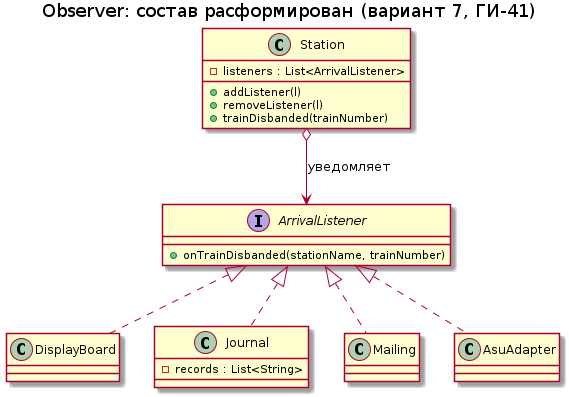

In [55]:
!plantuml -tpng observer.puml
from IPython.display import Image
Image("observer.png")

Вывод по задаче 2 (Чарачкин И. А., ГИ-41, вариант 7): Observer снял жёсткую связанность — класс `Station` больше не знает конкретных получателей уведомления о расформировании состава, четвёртый наблюдатель (`AsuAdapter`, передача в АСУ) добавлен без правки `Station`. Новые проблемы: порядок уведомлений определяется порядком подписки и не гарантирован; исключение в одном подписчике может прервать рассылку остальным (нужен try/catch вокруг вызова); забытая отписка оставляет ссылку на наблюдателя и приводит к утечке памяти.

---

## 5. Сравнение и выводы

### 5.1 Итоговая таблица

| Паттерн | Проблема кода «до» | Что добавляется без правки старого | Чем платим | Где применим в проекте |
|---|---|---|---|---|
| Strategy | `if/else` по типу внутри одного метода; метод отвечает и за выбор, и за расчёт | Новый класс-стратегия, реализующий интерфейс | Больше классов; выбор стратегии всё равно нужно где-то делать | Расчёт платы за перевозку (образец, раздел 2) |
| Factory Method | Создание отцепа по строковому типу через `if/else` | Новый продукт (`TransferTrainCut`) + новый создатель | Больше классов; косвенность создания | Создание отцепов по типу на сортировочной станции (вариант 7) |
| Observer | Источник события жёстко вызывает всех получателей | Новый слушатель, реализующий интерфейс | Управление подпиской/отпиской; порядок уведомлений; риск утечки | Оповещение о расформировании состава (вариант 7) |

### 5.2 Контрольные вопросы

1. Какой принцип SOLID нарушает разбор типа условным оператором и как каждый из трёх паттернов его восстанавливает?
   **Ответ:** Разбор типа условным оператором нарушает Open/Closed (каждое новое требование правит старый метод) и Single Responsibility (метод и выбирает, и делает). Strategy выносит варианты расчёта в классы, Factory Method — создание отцепов в создателей, Observer — реакцию на событие в слушателей: новое добавляется новым классом.
2. Чем Factory Method отличается от статического метода создания (`static factory method`) и от Abstract Factory?
   **Ответ:** Factory Method — наследование: подкласс-создатель решает, какой отцеп создать. Static factory method — просто статический метод, возвращающий объект (часто с именем), без наследования создателей. Abstract Factory — создаёт целые семейства связанных продуктов.
3. Strategy и State имеют почти одинаковую структуру классов. В чём разница по назначению?
   **Ответ:** Strategy — алгоритм выбирает клиент, стратегии независимы. State — состояние меняется само (переходами), и поведение объекта меняется вместе с состоянием.
4. Почему Observer может привести к утечке памяти и как этого избежать?
   **Ответ:** Субъект хранит сильные ссылки на наблюдателей; если наблюдатель не отписался, GC его не удалит. Решение: явный `removeListener`, слабые ссылки (`WeakReference`) или автоотписка по времени жизни.
5. Приведите пример, когда введение паттерна **вредно**. Что такое преждевременное усложнение?
   **Ответ:** Паттерн вреден, если изменение, ради которого он вводится, никогда не наступит: например, оборачивать в Strategy единственную формулу очерёдности расформирования, которая не будет меняться. Это и есть преждевременное усложнение — лишние классы и косвенность без выгоды.

### 5.3 Три вывода по работе в целом

1. Паттерны убирают `if/else` по типу, заменяя его полиморфизмом: новый тип отцепа или новый слушатель добавляется новым классом, а старый код не правится (OCP).
2. Плата за это — больше классов и косвенности; паттерн оправдан, когда изменение реально ожидается.
3. Проверки `[OK]/[FAIL]` доказывают, что поведение после рефакторинга не изменилось, а новое требование добавлено без правки существующих классов.

---

## 6. Варианты предметных областей

Номер варианта — по номеру студента в списке группы. Образец (раздел 2) выполняется всеми одинаково; задачи 1 и 2 — на своей предметной области.

| № | Предметная область | Фабрика создаёт | Стратегия варьирует | Наблюдатели получают событие |
|---|---|---|---|---|
| 1 | Грузовая станция | тип вагона | расчёт платы за пользование вагонами | вагон подан под погрузку |
| 2 | Локомотивное депо | вид ремонта (ТО-2, ТР-1, ТР-2) | приоритет заявок на ремонт | локомотив выдан из ремонта |
| 3 | Пассажирская касса | тип проездного документа | начисление скидки | рейс задержан |
| 4 | Контейнерный терминал | тип контейнера | выбор места на площадке | контейнер прибыл |
| 5 | Автотранспортное предприятие | тип транспортного средства | расчёт расхода топлива | путевой лист закрыт |
| 6 | Склад | тип тары | правило размещения (FIFO, ABC) | запас ниже нормы |
| 7 | Сортировочная станция | тип отцепа | очерёдность расформирования | состав расформирован |
| 8 | Пригородные перевозки | тип абонемента | тарификация по зонам | изменено расписание |
| 9 | Пункт таможенного оформления | тип декларации | выбор канала контроля | груз оформлен |
| 10 | Экспедиторская компания | тип заявки (авто, ж. д., море) | выбор перевозчика по критерию | статус отправки изменён |
| 11 | Путевое хозяйство | тип дефекта рельса | назначение вида работ | обнаружен дефект |
| 12 | Энергодиспетчерский пункт | тип потребителя | тарифный план (день, ночь) | авария на подстанции |
| 13 | Вагонное депо | тип неисправности | выбор отцепочного или безотцепочного ремонта | вагон забракован |
| 14 | Логистический центр | тип упаковки | правило консолидации отправок | сформирована отправка |
| 15 | Центр фирменного транспортного обслуживания | тип договора | расчёт скидки за объём | заявка согласована |

---

## 7. Чек-лист самопроверки

- [ ] Раздел 1 выполнен, версия Java не ниже 11
- [ ] `TariffBefore.java` и `TariffAfter.java` запущены, вывод сохранён
- [ ] Отвечены вопросы к образцу (п. 2.5)
- [ ] `FactoryAfter.java` написан, все проверки `[OK]`, в `main` нет разбора типов
- [ ] Четвёртый тип вагона добавлен новым классом
- [ ] `ObserverAfter.java` написан, все проверки `[OK]`, отписка работает
- [ ] Четвёртый наблюдатель добавлен без правки класса `Station`
- [ ] Построены три диаграммы: `strategy.puml`, `factory.puml`, `observer.puml`
- [ ] Заполнена итоговая таблица (п. 5.1)
- [ ] Отвечены пять контрольных вопросов и сформулированы три вывода
- [ ] Блокнот выполняется сверху вниз без ошибок после *Среда выполнения → Перезапустить и выполнить все*
- [ ] Запущена ячейка самопроверки, её вывод вставлен в описание pull request

## 8. Ячейка самопроверки

Ячейка сама компилирует и запускает все три файла, проверяет отсутствие `[FAIL]`, наличие диаграмм и минимальные признаки соблюдения требований. Запускать после того, как задачи выполнены.

In [59]:

import os, re, subprocess, datetime

ФИО_исполнителя = "Чарачкин Илья Александрович"  #@param {type:"string"}
Группа_исполнителя = "ГИ-41"  #@param {type:"string"}
Номер_варианта = 7  #@param {type:"integer"}
ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ = True  #@param {type:"boolean"}

ПРОГРАММЫ = [
    ("Образец, Strategy", "TariffAfter.java"),
    ("Задача 1, Factory Method", "FactoryAfter.java"),
    ("Задача 2, Observer", "ObserverAfter.java"),
]
ДИАГРАММЫ = ["strategy.puml", "factory.puml", "observer.puml"]

def запустить(имя_файла):
    """Запустить один исходный файл Java и вернуть (успех, пояснение)."""
    if not os.path.exists(имя_файла):
        return False, "файл отсутствует"
    завершение = subprocess.run(["java", имя_файла], capture_output=True, text=True, timeout=180)
    вывод = завершение.stdout + завершение.stderr
    if завершение.returncode != 0:
        значимые = [s for s in вывод.splitlines() if s.strip() and not s.startswith("Picked up")]
        первая_строка = значимые[0] if значимые else "без сообщения"
        return False, "аварийное завершение: " + первая_строка[:90]
    if "[FAIL]" in вывод:
        return False, "проверок не пройдено: %d" % вывод.count("[FAIL]")
    успешных = вывод.count("[OK]")
    if успешных < 3:
        return False, "проверок в файле только %d, требуется не менее 3" % успешных
    return True, "проверок пройдено: %d" % успешных

результаты = []
for название, файл in ПРОГРАММЫ:
    результаты.append((название, файл) + запустить(файл))

# Признаки соблюдения требований, которые можно проверить по тексту
замечания = []
def тело_метода(исходный_текст, сигнатура="main("):
    """Вернуть тело метода по сопоставлению фигурных скобок (без построчных комментариев)."""
    без_комментариев = re.sub(r"//[^\n]*", "", исходный_текст)
    начало = без_комментариев.find(сигнатура)
    if начало < 0:
        return ""
    открывающая = без_комментариев.find("{", начало)
    if открывающая < 0:
        return ""
    глубина = 0
    for позиция in range(открывающая, len(без_комментариев)):
        символ = без_комментариев[позиция]
        if символ == "{":
            глубина += 1
        elif символ == "}":
            глубина -= 1
            if глубина == 0:
                return без_комментариев[открывающая:позиция + 1]
    return без_комментариев[открывающая:]

if os.path.exists("FactoryAfter.java"):
    текст_фабрики = open("FactoryAfter.java", encoding="utf-8").read()
    блок_main = тело_метода(текст_фабрики)
    if re.search(r'\b(if|switch)\b', блок_main):
        замечания.append("в FactoryAfter.java метод main содержит ветвление по типу")
    if текст_фабрики.count("class ") < 5:
        замечания.append("в FactoryAfter.java меньше пяти классов: продукты, создатели и четвёртый тип, вероятно, не описаны")
if os.path.exists("ObserverAfter.java"):
    текст_наблюдателя = open("ObserverAfter.java", encoding="utf-8").read()
    for требуемое in ("addListener", "removeListener"):
        if требуемое not in текст_наблюдателя:
            замечания.append("в ObserverAfter.java нет метода %s" % требуемое)
отсутствующие_диаграммы = [d for d in ДИАГРАММЫ if not os.path.exists(d)]

строки = [
    "### Отчёт самопроверки «Песочница паттернов GoF»",
    "",
    "| Параметр | Значение |",
    "|---|---|",
    "| Исполнитель | %s, группа %s, вариант %d |" % (
        ФИО_исполнителя or "НЕ УКАЗАН", Группа_исполнителя or "НЕ УКАЗАНА", Номер_варианта),
    "| Дата и время отчёта (UTC) | %s |" % datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"),
    "| Версия Java | %s |" % next(
        (s for s in subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()
         if "version" in s), "не определена"),
    "",
    "| Программа | Файл | Результат |",
    "|---|---|---|",
]
for название, файл, успех, пояснение in результаты:
    строки.append("| %s | `%s` | %s — %s |" % (название, файл, "пройдено" if успех else "НЕ ПРОЙДЕНО", пояснение))
строки += [
    "",
    "| Диаграммы | %s |" % ("все три на месте" if not отсутствующие_диаграммы
                            else "отсутствуют: " + ", ".join(отсутствующие_диаграммы)),
    "| Таблица и выводы | %s |" % ("заполнены" if ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ else "НЕ ЗАПОЛНЕНЫ"),
    "| Замечания | %s |" % ("нет" if not замечания else "; ".join(замечания)),
]
print("\n".join(строки))
print("\nСкопируйте отчёт выше в описание pull request.\n")

ошибки = []
if not ФИО_исполнителя.strip() or not Группа_исполнителя.strip():
    ошибки.append("не указаны ФИО и группа")
ошибки += ["%s: %s" % (название, пояснение) for название, файл, успех, пояснение in результаты if not успех]
if отсутствующие_диаграммы:
    ошибки.append("нет диаграмм: " + ", ".join(отсутствующие_диаграммы))
if not ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ:
    ошибки.append("не заполнены итоговая таблица и выводы")
ошибки += замечания

assert not ошибки, "Работа не готова к сдаче: " + "; ".join(ошибки)
print("Самопроверка пройдена: работа готова к сдаче.")

### Отчёт самопроверки «Песочница паттернов GoF»

| Параметр | Значение |
|---|---|
| Исполнитель | Чарачкин Илья Александрович, группа ГИ-41, вариант 7 |
| Дата и время отчёта (UTC) | 2026-11-09 09:54 |
| Версия Java | openjdk version "21.0.12.1" 2026-08-18 |

| Программа | Файл | Результат |
|---|---|---|
| Образец, Strategy | `TariffAfter.java` | пройдено — проверок пройдено: 5 |
| Задача 1, Factory Method | `FactoryAfter.java` | пройдено — проверок пройдено: 4 |
| Задача 2, Observer | `ObserverAfter.java` | пройдено — проверок пройдено: 4 |

| Диаграммы | все три на месте |
| Таблица и выводы | заполнены |
| Замечания | нет |

Скопируйте отчёт выше в описание pull request.

Самопроверка пройдена: работа готова к сдаче.


---

## 9. Критерии оценивания

| Критерий | Баллов |
|---|---|
| Образец запущен, вопросы п. 2.5 отвечены содержательно | 10 |
| Factory Method: корректная структура паттерна, в `main` нет разбора типов | 20 |
| Factory Method: четвёртый тип добавлен новым классом | 10 |
| Observer: корректная структура, работают подписка и отписка | 20 |
| Observer: четвёртый наблюдатель добавлен без правки субъекта | 10 |
| Проверки в каждом файле осмысленны (не `[OK]` ради `[OK]`) | 10 |
| Три диаграммы классов соответствуют коду | 10 |
| Итоговая таблица, контрольные вопросы, выводы | 10 |
| **Итого** | **100** |

Снижение: задача решена не на своём варианте — минус 20; код «после» повторяет разбор типа условным оператором внутри нового класса — минус 20; диаграмма не соответствует коду — минус 10.

## 10. Для желающих (сверх задания)

| Что сделать | Зачем |
|---|---|
| Подключить настоящий JUnit 5 вместо метода `check`: `!wget -q https://repo1.maven.org/maven2/org/junit/platform/junit-platform-console-standalone/1.10.2/junit-platform-console-standalone-1.10.2.jar` и запуск через `java -jar` | переход к инструменту, который используется в ЛР по модульному тестированию |
| Заменить три `if` в выборе стратегии на `java.util.Map` с ключом-перечислением (`enum`) | показать, что каталог стратегий сам может быть устранён из вызывающего кода |
| Реализовать Observer на `java.util.function.Consumer` вместо своего интерфейса | сравнить классический GoF и функциональный стиль |